# Independent kidney cohort: coordinate and fragmentomic baselines across depth (Supp. Fig. X)

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

Frozen, Cristiano-trained models applied to the 12 independent kidney-cohort
samples (6 kidney cancer, 6 healthy) at 10,000-100,000 fragments per sample.
Lines are the mean ROC AUC over 10 with-replacement bags per depth (smaller
depths are nested prefixes of the 100k bags); shading is the paired
class-stratified hierarchical-bootstrap 95% CI (2,000 iterations). Panels:
a, reference models; b, binned fragment counts at four resolutions (~300, ~100,
~30 and ~10 kb = 10,000, 30,000, 100,000 and 300,000 genome-wide bins);
c, bins + fragment-length percentiles; d, bins + the DELFI features. LEAF-1 is
drawn in every panel as the common reference.

Lines are the mean of the per-bag AUCs (`cfdna_kidney_condition_metrics.csv`)
and bands the bootstrap CI (`cfdna_kidney_bootstrap_depth_summary.csv`): the
source run's `output_bootstrap/summary/{condition_metrics,depth_summary}.csv`.

The source plot script reads its colours and markers from
`09_plot_subsampling_v2.py`, which is not on this server, so the panel is
redrawn here from the two summary tables. Against the source figure: LEAF-1
takes its blue (it was a black dashed line), fragment length moves to
near-black (it shared the sky blue of the ~100 kb bins), the title, subtitle and
footnote move to the legend, panel letters a-d are added, and the width is
180 mm. Values and bands are unchanged.

Panel:
- `cfdna_kidney_coordinate_baselines_depth`

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: cfdna/data
OUT : cfdna/output


In [2]:
# ── Constants and data ────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DEPTHS = [10000, 25000, 50000, 75000, 100000]
BIN_N = [10000, 30000, 100000, 300000]
BIN_TXT = {10000: "~300 kb", 30000: "~100 kb", 100000: "~30 kb", 300000: "~10 kb"}
# (colour, linestyle, marker) -- every series differs in all three, so no pair
# relies on colour alone.
REF_STYLE = {"leaf1": ("#0072B2", (0, (4, 1.6)), "o"),
             "delfi": ("#D55E00", "-", "s"),
             "length": ("#2B2B2B", ":", "^")}
BIN_STYLE = {10000: ("#009E73", "-", "^"), 30000: ("#56B4E9", "--", "v"),
             100000: ("#CC79A7", "-.", "D"), 300000: ("#882255", ":", "P")}
REF_LABEL = {"leaf1": "LEAF-1", "delfi": "DELFI", "length": "Fragment length"}
PANELS = [("Reference models", ["leaf1", "delfi", "length"], 1),
          ("Genome-bin resolutions", ["leaf1"] + [f"genome_bin_{n}" for n in BIN_N], 2),
          ("Genome bins + fragment length", ["leaf1", "length"] + [f"bin_length_{n}" for n in BIN_N], 2),
          ("Genome bins + DELFI", ["leaf1", "delfi"] + [f"bin_delfi_{n}" for n in BIN_N], 2)]
PANEL_RC = {"font.size": 6, "axes.titlesize": 6.5, "axes.labelsize": 6.5,
            "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 5.5}

SHOWN = sorted({m for _, models, _ in PANELS for m in models})

# Bands: the paired class-stratified hierarchical-bootstrap 95% CI of the source run.
summ = pd.read_csv(DATA / "cfdna_kidney_bootstrap_depth_summary.csv", float_precision="round_trip")
d = (summ[summ.model.isin(SHOWN)]
     .rename(columns={"ci95_low": "auc_band_low", "ci95_high": "auc_band_high"})
     .reset_index(drop=True))
assert sorted(d.sample_size.unique()) == DEPTHS and set(d.n_effective_repeats) == {10}
assert (d.groupby("model").size() == len(DEPTHS)).all() and d.model.nunique() == len(SHOWN)

# Lines: the mean of the 10 per-bag AUCs, checked against the summary's own mean.
bags = pd.read_csv(DATA / "cfdna_kidney_condition_metrics.csv", float_precision="round_trip")
per = (bags.groupby(["model", "sample_size"]).roc_auc
           .agg(n_bags="count", auc_mean="mean").reset_index())
d = d.merge(per, on=["model", "sample_size"], how="left", validate="one_to_one")
assert (d.n_bags == 10).all()
max_diff = np.abs(d.auc_mean - d.mean_roc_auc).max()
assert max_diff < 1e-12, max_diff
n_samples = int(bags.n_samples.iloc[0])
print(f"{len(d)} line points from {len(bags)} per-bag AUCs; max |diff| vs summary mean {max_diff:.1e}")


def style_of(model):
    if model in REF_STYLE:
        return REF_STYLE[model] + (REF_LABEL[model],)
    n = int(model.rsplit("_", 1)[1])
    return BIN_STYLE[n] + (BIN_TXT[n],)

75 line points from 1100 per-bag AUCs; max |diff| vs summary mean 1.1e-16


saved: cfdna/output/cfdna_kidney_coordinate_baselines_depth.pdf
saved: cfdna/output/cfdna_kidney_coordinate_baselines_depth.png
saved: cfdna/output/cfdna_kidney_coordinate_baselines_depth.svg
saved: cfdna/output/cfdna_kidney_coordinate_baselines_depth.tsv


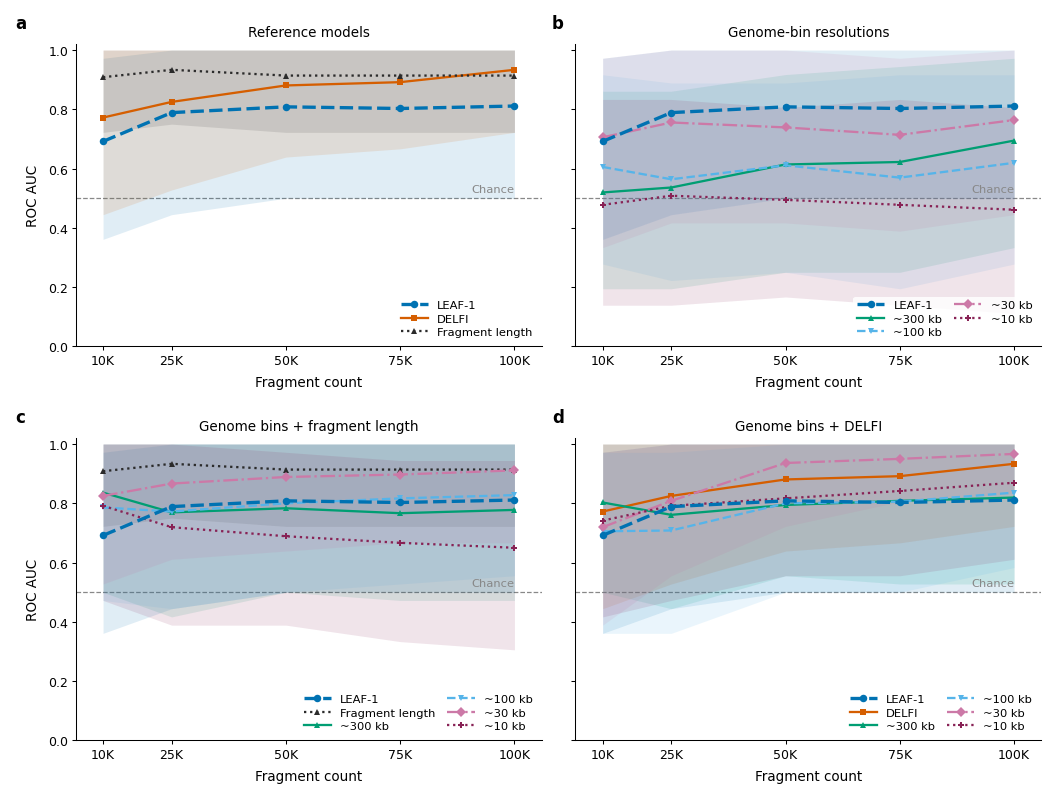

n = 12 samples; at 100K fragments:
                      auc_mean  auc_band_low  auc_band_high
label                                                      
bin_delfi (~300 kb)      0.819         0.528          1.000
bin_delfi (~30 kb)       0.967         0.833          1.000
bin_delfi (~100 kb)      0.836         0.583          1.000
bin_delfi (~10 kb)       0.869         0.611          1.000
bin_length (~300 kb)     0.778         0.472          1.000
bin_length (~30 kb)      0.911         0.667          1.000
bin_length (~100 kb)     0.828         0.556          1.000
bin_length (~10 kb)      0.650         0.306          0.944
DELFI                    0.933         0.722          1.000
genome_bin (~300 kb)     0.694         0.333          0.972
genome_bin (~30 kb)      0.764         0.444          1.000
genome_bin (~100 kb)     0.619         0.278          0.917
genome_bin (~10 kb)      0.461         0.111          0.806
LEAF-1                   0.811         0.500          1.000
Fragm

In [3]:
# ── Figure ─────────────────────────────────────────────────────────────────────
with plt.rc_context(PANEL_RC):
    fig, axes = plt.subplots(2, 2, figsize=(6.95, 5.3), sharey=True)
    for ax, (title, models, ncol), letter in zip(axes.ravel(), PANELS, "abcd"):
        for model in models:
            color, ls, marker, label = style_of(model)
            s = d[d.model == model].sort_values("sample_size")
            ref = model == "leaf1"
            ax.fill_between(s.sample_size, s.auc_band_low, s.auc_band_high, color=color,
                            alpha=0.12, linewidth=0, zorder=1)
            ax.plot(s.sample_size, s.auc_mean, color=color, ls=ls, marker=marker,
                    lw=1.6 if ref else 1.1, ms=3.6 if ref else 3.2,
                    markeredgewidth=0, label=label, zorder=4 if ref else 3)
        ax.axhline(0.5, color="#888888", ls="--", lw=0.6, zorder=0)
        ax.text(DEPTHS[-1], 0.515, "Chance", ha="right", va="bottom", fontsize=5.5, color="#888888")
        ax.set_xticks(DEPTHS); ax.set_xticklabels([f"{x // 1000}K" for x in DEPTHS])
        ax.set_xlim(DEPTHS[0] - 6000, DEPTHS[-1] + 6000)
        ax.set_ylim(0, 1.02); ax.set_yticks(np.arange(0, 1.01, 0.2))
        ax.set_xlabel("Fragment count")
        ax.set_title(title, pad=4)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(axis="both", length=2, pad=1.5, width=0.5)
        ax.legend(loc="lower right", ncol=ncol, frameon=True, framealpha=0.85, edgecolor="none",
                  handlelength=2.4, columnspacing=1.0, labelspacing=0.3, borderpad=0.3)
        ax.text(-0.13 if letter in "ac" else -0.05, 1.04, letter, transform=ax.transAxes,
                fontsize=8, fontweight="bold", va="bottom")
    for ax in axes[:, 0]:
        ax.set_ylabel("ROC AUC")
    fig.tight_layout(h_pad=1.6, w_pad=1.2)
    savefig(fig, OUT, "cfdna_kidney_coordinate_baselines_depth", data=d)
    plt.show()

at100 = (d[d.sample_size == 100000].assign(label=[style_of(m)[3] if m in REF_STYLE else f"{m.rsplit('_', 1)[0]} ({style_of(m)[3]})" for m in d[d.sample_size == 100000].model])
         .set_index("label")[["auc_mean", "auc_band_low", "auc_band_high"]])
print(f"n = {n_samples} samples; at 100K fragments:")
print(at100.round(3).to_string())